# RBM se Network Intrusion Detection + Root Cause (NSL-KDD)

**Idea (simple):** RBM ko sirf *normal* traffic dikhao. Jab kuch ajeeb aaye, uski **free energy high** aati hai = **attack**.
Phir dekhte hain **kaunse features sabse ajeeb the** = probable cause (RCA).

**Notebook flow:** Data → Preprocess → RBM (CD-k) → Threshold → Evaluate → Baseline → RCA → Save for webapp

In [1]:
import os, urllib.request, pickle, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, confusion_matrix, roc_curve

np.random.seed(42)
BASE = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
for f in ["KDDTrain+.txt", "KDDTest+.txt"]:
    if not os.path.exists(f):
        print("downloading", f)
        urllib.request.urlretrieve(BASE + f, f)
print("files ready")

files ready


## 1. Data load
NSL-KDD me 41 features + label + difficulty hota hai.

In [2]:
cols = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment","urgent","hot",
"num_failed_logins","logged_in","num_compromised","root_shell","su_attempted","num_root","num_file_creations","num_shells",
"num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count","srv_count","serror_rate","srv_serror_rate",
"rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count","dst_host_srv_count",
"dst_host_same_srv_rate","dst_host_diff_srv_rate","dst_host_same_src_port_rate","dst_host_srv_diff_host_rate",
"dst_host_serror_rate","dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty"]

train = pd.read_csv("KDDTrain+.txt", names=cols)
test  = pd.read_csv("KDDTest+.txt",  names=cols)

# attack name -> 4 category
cat_map = {"normal":"Normal"}
for a in ["back","land","neptune","pod","smurf","teardrop","apache2","udpstorm","processtable","mailbomb","worm"]: cat_map[a]="DoS"
for a in ["satan","ipsweep","nmap","portsweep","mscan","saint"]: cat_map[a]="Probe"
for a in ["guess_passwd","ftp_write","imap","phf","multihop","warezmaster","warezclient","spy","xlock","xsnoop","snmpguess","snmpgetattack","httptunnel","sendmail","named"]: cat_map[a]="R2L"
for a in ["buffer_overflow","loadmodule","rootkit","perl","sqlattack","xterm","ps"]: cat_map[a]="U2R"

for d in (train, test):
    d["category"] = d["label"].map(cat_map).fillna("Other")
    d["is_attack"] = (d["label"] != "normal").astype(int)

print("Train:", train.shape, "| Test:", test.shape)
print("\nTrain categories:\n", train.category.value_counts())
print("\nTest categories:\n", test.category.value_counts())

Train: (125973, 45) | Test: (22544, 45)

Train categories:
 category
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Test categories:
 category
Normal    9711
DoS       7460
R2L       2885
Probe     2421
U2R         67
Name: count, dtype: int64


## 2. Preprocessing
- Heavy-tail columns pe `log1p` (src_bytes jaise bade numbers RBM ko bigaadte hain)
- Categorical → one-hot

In [ ]:
cat_cols = ["protocol_type", "service", "flag"]
log_cols = ["duration", "src_bytes", "dst_bytes", "hot", "num_compromised", "num_root", "num_file_creations",
            "count", "srv_count", "dst_host_count", "dst_host_srv_count"]

all_services = sorted(set(train.service) | set(test.service))
all_flags    = sorted(set(train.flag)    | set(test.flag))
all_protos   = sorted(set(train.protocol_type) | set(test.protocol_type))
cat_levels = {"protocol_type": all_protos, "service": all_services, "flag": all_flags}

num_cols = [c for c in cols if c not in cat_cols + ["label", "difficulty"]]   #label is target and difficulty is metadata

def to_matrix(df):
    X = df[num_cols].astype(float).copy()
    for c in log_cols:
        X[c] = np.log1p(X[c])
    for c, levels in cat_levels.items():
        for lv in levels:
            X[f"{c}={lv}"] = (df[c] == lv).astype(float)
    return X

X_train_all = to_matrix(train)
X_test_all  = to_matrix(test)
feature_names = list(X_train_all.columns)

normal_mask = (train.is_attack == 0).values
scaler = MinMaxScaler().fit(X_train_all[normal_mask])

def prep(X):
    return np.clip(scaler.transform(X), 0, 1).astype(np.float32)   #clipping for testing observation as training scales will be used for scaling

Xn = prep(X_train_all[normal_mask])          # sirf normal trainign rows
Xte = prep(X_test_all); yte = test.is_attack.values    #testing rows and yte is test labels

# normal ko train/validation me todo (threshold ke liye validation chahiye)   calibrating the threshold
idx = np.random.permutation(len(Xn)); cut = int(0.9 * len(Xn))   
Xtr, Xval = Xn[idx[:cut]], Xn[idx[cut:]]
print("RBM train:", Xtr.shape, "| validation (normal):", Xval.shape, "| test:", Xte.shape)

/tmp/ipykernel_129/1174853252.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[f"{c}={lv}"] = (df[c] == lv).astype(float)
/tmp/ipykernel_129/1174853252.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[f"{c}={lv}"] = (df[c] == lv).astype(float)


RBM train: (60608, 122) | validation (normal): (6735, 122) | test: (22544, 122)


## 3. RBM (numpy) — CD-k training + Free Energy

- **Visible units** = features, **hidden units** = learned "traffic patterns"
- **CD-k** = Contrastive Divergence, k baar Gibbs sampling (Obj 3)
- **Free energy** `F(v) = -v·b - Σ log(1 + exp(c + vW))` → low = normal, high = anomaly

In [ ]:
def sigmoid(x): return 1.0 / (1.0 + np.exp(-x))

class RBM:
    def __init__(self, n_vis, n_hid, seed=0):
        r = np.random.RandomState(seed)     #random number generator for initializing weights and sampling hidden and visible states.
        self.W = r.normal(0, 0.01, (n_vis, n_hid)).astype(np.float32)  #Initializes the weight matrix using small random values drawn from a normal distribution with mean 0 and standard deviation 0.01.
        self.b = np.zeros(n_vis, dtype=np.float32)   # visible bias
        self.c = np.zeros(n_hid, dtype=np.float32)   # hidden bias
        self.r = r   #Stores the random number generator inside the model

    def h_prob(self, v): return sigmoid(v @ self.W + self.c)
    def v_prob(self, h): return sigmoid(h @ self.W.T + self.b)   #calculates reconstructed visible probabilities from hidden-unit states.

    def free_energy(self, v):
        return -(v @ self.b) - np.logaddexp(0, v @ self.W + self.c).sum(axis=1)

    def fit(self, X, epochs=15, lr=0.05, k=1, batch=128, verbose=True):   
        n = len(X); hist = []  #hist stores the reconstruction error after evry epoch
        for ep in range(epochs):
            perm = self.r.permutation(n); err = 0.0
            for i in range(0, n, batch):
                v0 = X[perm[i:i+batch]]
                ph0 = self.h_prob(v0)
                h = (self.r.rand(*ph0.shape) < ph0).astype(np.float32)
                vk = v0
                for _ in range(k):                      # Gibbs sampling chain
                    pv = self.v_prob(h)
                    vk = (self.r.rand(*pv.shape) < pv).astype(np.float32)
                    phk = self.h_prob(vk)
                    h = (self.r.rand(*phk.shape) < phk).astype(np.float32)
                m = len(v0)  #batch size
                self.W += lr * (v0.T @ ph0 - vk.T @ phk) / m      #phk hidden porbability and vk is visible layer
                self.b += lr * (v0 - vk).mean(0)    #take mean across batch
                self.c += lr * (ph0 - phk).mean(0)  #update hidden biases
                err += ((v0 - pv) ** 2).sum()   # accumalaitng reconstruction error
            hist.append(err / n)
            if verbose: print(f"epoch {ep+1:2d}/{epochs}  recon_err={hist[-1]:.4f}")   #verbose controls the logs length
        return hist

    def reconstruct(self, v):                           # 1 deterministic Gibbs step
        return self.v_prob(self.h_prob(v))

epoch  1/15  recon_err=2.2374


epoch  2/15  recon_err=1.6316


epoch  3/15  recon_err=1.3224


epoch  4/15  recon_err=1.1090


epoch  5/15  recon_err=0.9178


...

epoch 11/15  recon_err=0.6985


epoch 12/15  recon_err=0.6756


epoch 13/15  recon_err=0.6547


epoch 14/15  recon_err=0.6346


epoch 15/15  recon_err=0.6191

Training time: 5.5s


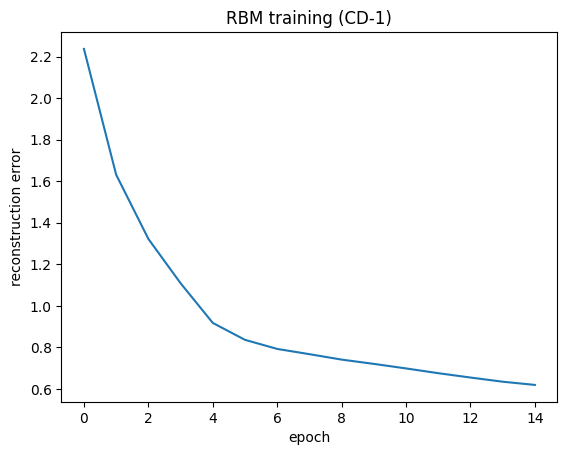

In [5]:
t0 = time.time()
rbm = RBM(n_vis=Xtr.shape[1], n_hid=64)
hist_cd1 = rbm.fit(Xtr, epochs=15, lr=0.05, k=1)
print(f"\nTraining time: {time.time()-t0:.1f}s")

plt.plot(hist_cd1); plt.xlabel("epoch"); plt.ylabel("reconstruction error"); plt.title("RBM training (CD-1)"); plt.show()

## 4. Threshold + Evaluation
Threshold = normal *validation* ki free energy ka **95th percentile** (matlab ~5% normal ko galat alert milega).

In [ ]:
fe_val = rbm.free_energy(Xval)
threshold = np.percentile(fe_val, 95)
fe_te = rbm.free_energy(Xte)       #contian free energy scores
pred = (fe_te > threshold).astype(int)  # 1 attack

print(f"Threshold (free energy): {threshold:.3f}")
print(f"AUC-ROC : {roc_auc_score(yte, fe_te):.4f}")
print(f"Precision: {precision_score(yte, pred):.4f} | Recall: {recall_score(yte, pred):.4f} | F1: {f1_score(yte, pred):.4f}")
print("Confusion matrix [[TN FP],[FN TP]]:\n", confusion_matrix(yte, pred))

# per attack category detection rate
res = test[["category"]].copy(); res["detected"] = pred
print("\nDetection rate per category:")
print(res.groupby("category").detected.mean().round(3))

Threshold (free energy): -65.278
AUC-ROC : 0.9689
Precision: 0.9701 | Recall: 0.7373 | F1: 0.8378
Confusion matrix [[TN FP],[FN TP]]:
 [[9419  292]
 [3371 9462]]

Detection rate per category:
category
DoS       0.911
Normal    0.030
Probe     0.879
R2L       0.173
U2R       0.612
Name: detected, dtype: float64


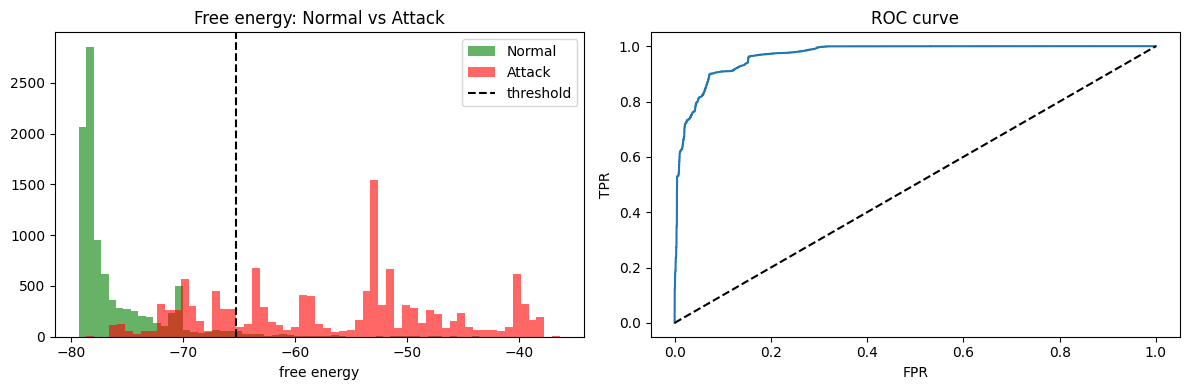

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(fe_te[yte == 0], bins=60, alpha=.6, label="Normal", color="green")
ax[0].hist(fe_te[yte == 1], bins=60, alpha=.6, label="Attack", color="red")
ax[0].axvline(threshold, color="k", ls="--", label="threshold")
ax[0].set_title("Free energy: Normal vs Attack"); ax[0].set_xlabel("free energy"); ax[0].legend()
fpr, tpr, _ = roc_curve(yte, fe_te)
ax[1].plot(fpr, tpr); ax[1].plot([0,1],[0,1],"k--"); ax[1].set_title("ROC curve"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR")
plt.tight_layout(); plt.show()

## 5. Ablation: CD-1 vs CD-5 aur hidden units 

In [8]:
rows = []
for k in [1, 5]:
    for nh in [32, 64, 128]:
        m = RBM(Xtr.shape[1], nh, seed=1); m.fit(Xtr, epochs=10, lr=0.05, k=k, verbose=False)
        f = m.free_energy(Xte)
        rows.append({"CD-k": k, "hidden": nh, "AUC": round(roc_auc_score(yte, f), 4)})
abl = pd.DataFrame(rows); print(abl.to_string(index=False))

 CD-k  hidden    AUC
    1      32 0.9659
    1      64 0.9656
    1     128 0.9658
    5      32 0.9692
    5      64 0.9682
    5     128 0.9690


## 6. Baseline: Isolation Forest

In [9]:
iso = IsolationForest(n_estimators=200, random_state=0).fit(Xtr)
s_iso = -iso.score_samples(Xte)
th_iso = np.percentile(-iso.score_samples(Xval), 95)
p_iso = (s_iso > th_iso).astype(int)

comp = pd.DataFrame({
    "Model": ["Isolation Forest", "RBM (free energy)"],
    "AUC":  [roc_auc_score(yte, s_iso), roc_auc_score(yte, fe_te)],
    "F1":   [f1_score(yte, p_iso), f1_score(yte, pred)],
    "Recall": [recall_score(yte, p_iso), recall_score(yte, pred)]}).round(4)
print(comp.to_string(index=False))

            Model    AUC     F1  Recall
 Isolation Forest 0.9487 0.7838  0.6574
RBM (free energy) 0.9689 0.8378  0.7373


## 7. Root Cause Analysis (RCA)

RBM sirf "attack hai" batata hai. **Kyun** — iske liye:
1. Input ko RBM se reconstruct karo
2. Har feature ka error nikalo, normal ke mukable **kitna zyada** hai (z-score)
3. One-hot columns ko wapas original feature (`service`, `flag`...) me jod do
4. Top features → rule map → probable cause

In [ ]:
# original feature name for each column (one-hot -> parent column)
parent = [f.split("=")[0] for f in feature_names]    #groupng one hot columns
groups = {}
for i, p in enumerate(parent): groups.setdefault(p, []).append(i)   #storing indices of features

def feat_err(X):
    e = (X - rbm.reconstruct(X)) ** 2
    return np.stack([e[:, ix].sum(1) for ix in groups.values()], axis=1)

group_names = list(groups.keys())
E_val = feat_err(Xval)                       #grouped reconstructin error
mu, sd = E_val.mean(0), E_val.std(0) + 1e-6   #avg error of feature group

cause_rules = [
    ({"serror_rate","srv_serror_rate","dst_host_serror_rate","dst_host_srv_serror_rate","count","srv_count","flag"}, "SYN flood / DoS pattern"),
    ({"diff_srv_rate","dst_host_diff_srv_rate","rerror_rate","srv_rerror_rate","dst_host_rerror_rate","dst_host_srv_diff_host_rate","service"}, "Port scan / Probe pattern"),
    ({"num_failed_logins","hot","is_guest_login","logged_in"}, "Brute-force / unauthorized login (R2L)"),
    ({"root_shell","num_shells","su_attempted","num_root","num_file_creations","num_compromised"}, "Privilege escalation (U2R)"),
]

def explain(x_row, top_k=4):
    z = (feat_err(x_row[None, :])[0] - mu) / sd   #calculating z  
    order = np.argsort(-z)[:top_k]     #top+k are selected  [0.05, 0.02, 0.08, 0.01]
    top = [(group_names[i], round(float(z[i]), 2)) for i in order]  #list feature - error
    names = {t[0] for t in top}
    best, score = "Unknown / unusual traffic", 0
    for feats, cause in cause_rules:
        s = len(names & feats)
        if s > score: best, score = cause, s
    return top, best

def predict_one(x_row):
    fe = float(rbm.free_energy(x_row[None, :])[0])
    is_anom = fe > threshold
    out = {"anomaly": bool(is_anom), "free_energy": round(fe, 3), "threshold": round(float(threshold), 3)}
    if is_anom:
        top, cause = explain(x_row)
        out["top_features"] = top; out["probable_cause"] = cause
    return out

# demo: ek DoS, ek normal
import json
i_dos = test.index[test.category == "DoS"][0]; i_norm = test.index[test.category == "Normal"][0]
print("NORMAL row ->", json.dumps(predict_one(Xte[i_norm]), indent=1))
print("\nDoS row    ->", json.dumps(predict_one(Xte[i_dos]), indent=1))

NORMAL row -> {
 "anomaly": false,
 "free_energy": -72.229,
 "threshold": -65.278
}

DoS row    -> {
 "anomaly": true,
 "free_energy": -52.819,
 "threshold": -65.278,
 "top_features": [
  [
   "count",
   13.08
  ],
  [
   "same_srv_rate",
   11.17
  ],
  [
   "dst_host_same_srv_rate",
   5.13
  ],
  [
   "service",
   3.43
  ]
 ],
 "probable_cause": "SYN flood / DoS pattern"
}


In [11]:
# RCA ka quick check: DoS rows me kitni baar "SYN flood" aaya (jab detect hue)
chk = {}
for cat in ["DoS", "Probe", "R2L", "U2R"]:
    ids = np.where((test.category == cat).values & (pred == 1))[0][:300]
    chk[cat] = pd.Series([explain(Xte[i])[1] for i in ids]).value_counts(normalize=True).round(2).to_dict()
for k, v in chk.items(): print(k, "->", v)

DoS -> {'SYN flood / DoS pattern': 0.93, 'Port scan / Probe pattern': 0.04, 'Brute-force / unauthorized login (R2L)': 0.02, 'Unknown / unusual traffic': 0.01}
Probe -> {'Port scan / Probe pattern': 0.69, 'SYN flood / DoS pattern': 0.24, 'Unknown / unusual traffic': 0.07}
R2L -> {'Port scan / Probe pattern': 0.71, 'Brute-force / unauthorized login (R2L)': 0.22, 'SYN flood / DoS pattern': 0.05, 'Unknown / unusual traffic': 0.02, 'Privilege escalation (U2R)': 0.0}
U2R -> {'Privilege escalation (U2R)': 0.56, 'Port scan / Probe pattern': 0.32, 'SYN flood / DoS pattern': 0.05, 'Brute-force / unauthorized login (R2L)': 0.05, 'Unknown / unusual traffic': 0.02}


## 8. Webapp ke liye save karo

- `rbm_artifacts.pkl` → model, scaler, threshold, feature info (API me load hoga)
- `traffic_sample.csv` → **simulator** ke liye (raw rows + label + category)

In [12]:
artifacts = dict(W=rbm.W, b=rbm.b, c=rbm.c, threshold=float(threshold),
                 scaler=scaler, feature_names=feature_names, group_names=group_names,
                 groups=groups, mu=mu, sd=sd, cat_levels=cat_levels, num_cols=num_cols,
                 log_cols=log_cols, cols=cols, cause_rules=cause_rules)
with open("rbm_artifacts.pkl", "wb") as f: pickle.dump(artifacts, f)

# simulator sample: 1500 normal + 500 attack (mix), raw columns
samp = pd.concat([test[test.is_attack == 0].sample(1500, random_state=1),
                  test[test.is_attack == 1].sample(500, random_state=1)]).sample(frac=1, random_state=1)
samp.to_csv("traffic_sample.csv", index=False)
print("saved: rbm_artifacts.pkl, traffic_sample.csv", samp.shape)

saved: rbm_artifacts.pkl, traffic_sample.csv (2000, 45)


## Next: Webapp
1. **Simulator API** → `traffic_sample.csv` se `/next?attack_prob=0.1` pe ek-ek row bhejti hai
2. **Detector API** → `rbm_artifacts.pkl` load karke `/predict` me row lo, `predict_one()` jaisa result do
3. **Streamlit dashboard** → "Start Traffic" button + live free-energy chart + red alert + top causes